# Hausse de loyer Équinoxe — prévision 2026

**Question : quelle croissance du loyer effectif peut-on prévoir pour les transitions de bail en 2026 ?**

Ce notebook est dérivé des 24 cellules du `starter.ipynb` fourni : chargement, conventions Yardi,
effet de composition, appariement, concessions, renouvellements et prévision. Les fonctions non
implémentées sont complétées et les vérifications temporelles sont ajoutées. Les données sources
restent intactes et hors du dépôt. Aucun aperçu de ligne CRM n'est affiché.

La démarche : vérifier → définir → comparer → prévoir → tester → expliquer. Les calculs sont
reproduits depuis les quatre CSV locaux. Les petits helpers de lecture/vérification se trouvent dans
`equinoxe.py`; l'appariement et la prévision sont également visibles ici, sans modèle complexe caché.
Le document de passation anglais est `docs/PROJECT_CONTEXT.md`.

**Portée :** extrait de six immeubles, et non portefeuille complet. On ne peut pas en déduire
l'occupation, l'inoccupation, l'absorption ni le rôle total de loyers. Une date de fin en 2026 est une
condition contractuelle connue, pas un loyer 2026 observé. La présentation indique 4 303 baux;
les consignes écrites et le CSV en contiennent 4 302. On utilise le fichier vérifié.

## 1. Chargement local et intégrité — phases A et B

Installer les dépendances et définir `JADCO_DATA_DIR` selon le README. Aucun chemin absolu de
l'ordinateur n'est enregistré ici. Tous les fichiers du manifeste sont vérifiés par taille et SHA-256.
Les identifiants `h*`, `sPropCode` et `sUnitCode` sont lus comme chaînes; les zéros initiaux sont conservés.
Les prix, surfaces et indicateurs sont numériques; `s` ne signifie pas automatiquement « chaîne ».
Les dates sont converties avec contrôle des échecs. Une erreur d'intégrité arrête l'exécution.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

ROOT = Path.cwd().resolve()
if not (ROOT / "equinoxe.py").exists():
    ROOT = ROOT.parent
if not (ROOT / "equinoxe.py").exists():
    raise RuntimeError("Exécuter depuis la racine du dépôt ou notebooks/.")
sys.path.insert(0, str(ROOT))
from equinoxe import (
    UNIT_KEY, MIN_GAP_YEARS, MAX_GAP_YEARS, DAYS_PER_YEAR, HISTORY_YEARS,
    MIN_GROUP_PAIRS, MIN_GROUP_YEARS, METHODS, PRICE_COLUMNS,
    data_directory, verify_manifest, load_tables, audit_tables,
    validate_identity, known_leases, available_external, latest_asking, weighted_median,
)

pd.set_option("display.max_rows", 150)
pd.set_option("display.precision", 3)
COLORS = {"contractual": "#1976a3", "effective": "#d26a23", "naive": "#7655a6"}
plt.rcParams.update({"figure.figsize": (10, 4.8), "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 11, "axes.grid": True,
                     "grid.alpha": 0.2, "figure.dpi": 120})
DATA_DIR = data_directory()
display(verify_manifest(DATA_DIR))
tables = load_tables(DATA_DIR)
listings, leases, concessions, asking = (tables[name] for name in ["listings", "leases", "concessions", "asking"])
audit_summary, column_types, audit_checks = audit_tables(tables, DATA_DIR)
display(audit_summary)
display(column_types)
display(audit_checks)

,file,size_ok,sha256_ok
0,consignes.pdf,True,True
1,equinoxe_asking_history.csv,True,True
2,equinoxe_concessions.csv,True,True
3,equinoxe_lease_history.csv,True,True
4,equinoxe_listings.csv,True,True
5,presentation-jadco.pdf,True,True
6,starter.ipynb,True,True


,table,rows,columns,missing_cells,empty_cells,placeholder_cells,exact_duplicates
0,listings,1061,29,0,0,0,0
1,leases,4302,35,0,0,0,0
2,concessions,3560,18,0,0,0,0
3,asking,3857,14,0,0,0,0


,table,column,dtype,missing
0,listings,hProperty,string,0
1,listings,hUnit,string,0
2,listings,hBuilding,string,0
3,listings,sPropCode,string,0
4,listings,sUnitCode,string,0
5,listings,sBuilding,object,0
6,listings,sCity,object,0
7,listings,sState,object,0
8,listings,sAddr1,object,0
9,listings,sLatitude,float64,0


,table,check,count
0,listings,unmatched_unit_keys,0
1,listings,hUnit_key_disagreement,0
2,listings,unstable_hProperty,0
3,listings,listing_disagreement_hProperty,0
4,listings,unstable_hBuilding,0
5,listings,listing_disagreement_hBuilding,0
6,listings,unstable_sBuilding,0
7,listings,listing_disagreement_sBuilding,0
8,listings,unstable_sState,0
9,listings,listing_disagreement_sState,0


### Dictionnaire et interprétation des données

| Colonnes | Signification et usage |
|---|---|
| `hUnit`, `hProperty`, `hBuilding` | Handles Yardi : identifiants opaques, pas des grandeurs. |
| `sPropCode` + `sUnitCode` | Identité d'appartement pour trier/apparier; bijection avec `hUnit` vérifiée. |
| `sLink` | Identifiant/lien représentatif de l'unité; unicité vérifiée, contenu non publié. |
| `sSite`, `sBuilding`, `sCity`, `sState` | Étiquettes de regroupement; un site peut contenir plusieurs propriétés. |
| `sBeds`, `sBaths`, `sSqft`, `sFloor` | Chambres, salles de bain, surface en pi², étage; stabilité contrôlée. |
| `sRent` | Loyer mensuel contractuel du bail; dans listings, prix d'une observation de l'offre. |
| `sRentEffective` | Loyer mensuel effectif fourni, après avantages selon la source; pas une collecte de cash vérifiée. |
| `sLeaseFrom`, `sLeaseTo`, `sSignDate` | Début contractuel, fin contractuelle, date de signature. Le début attribue l'année de transition. |
| `sTermMonths`, `sTermSeq` | Durée et séquence stockées, contrôlées sans les utiliser comme clé globale de bail. |
| `sRenewal` | 1 : renouvellement; 0 : relocation, selon le nouveau bail. |
| `sConcession` | Indicateur 0/1 fourni; distinct du nombre de lignes de concessions. |
| `sChargeCode`, `sChargeDesc`, `sAmount`, `sMonths` | Type, description, montant signé et durée renseignée d'un avantage. Le sens total/mensuel n'est pas uniforme. |
| `sDateFrom`, `sDateTo` | Période renseignée de concession; peut dépasser 2025. Pas d'identifiant explicite du bail. |
| `sMonth`, `sAskingRent` | Mois et prix affiché observé; série irrégulière, distincte des loyers signés. |
| `sAsOf`, `sAvailable` | Date du relevé et disponibilité renseignée, sans preuve d'occupation réelle. |

Les contrôles de placeholders recherchent vide, null, none, na, n/a, nan, unknown, -, ?, 9999 et -999.
Ils ne prouvent pas l'absence de codes particuliers inconnus. Les collisions d'une clé de concession
ne sont pas des duplicatas de bail : plusieurs avantages peuvent avoir le même code et la même période.
On les conserve, sans jointure multiplicative ni reconstruction arbitraire du loyer effectif.

In [2]:
identity_summary = pd.Series({
    "listing_hUnit_distinct": listings.hUnit.nunique(),
    "listing_property_unit_distinct": listings.drop_duplicates(UNIT_KEY).shape[0],
    "unsafe_site_unit_collision_rows": int(listings.duplicated(["sSite", "sUnitCode"], keep=False).sum()),
    "maximum_links_per_unit": int(leases.groupby(UNIT_KEY).sLink.nunique().max()),
    "maximum_units_per_link": int(leases.groupby("sLink").hUnit.nunique().max()),
    "leading_zero_unit_codes": int(listings.sUnitCode.str.startswith("0").sum()),
    "listing_asof_min": listings.sAsOf.min().date().isoformat(),
    "listing_asof_max": listings.sAsOf.max().date().isoformat(),
})
display(identity_summary.to_frame("value"))
display(listings.groupby(["sState", "sCity", "sBuilding"]).size().rename("apartments").to_frame())
display(leases[["sRenewal", "sConcession"]].apply(pd.Series.value_counts).fillna(0).astype(int))
additional_stability = []
for column in ["sBaths", "sUnitType", "sUnitSubtype", "sLink"]:
    linked = leases.merge(listings[UNIT_KEY + [column]], on=UNIT_KEY, how="left",
                          validate="many_to_one", suffixes=("", "_listing"))
    additional_stability.append({"column": column,
        "unstable_units": int(leases.groupby(UNIT_KEY)[column].nunique().gt(1).sum()),
        "listing_disagreement_rows": int(linked[column].ne(linked[column + "_listing"]).sum())})
display(pd.DataFrame(additional_stability))
display(leases[["sLeaseFrom", "sLeaseTo", "sSignDate", "sTermMonths"]].agg(["min", "max"]))

,value
listing_hUnit_distinct,1061
listing_property_unit_distinct,1061
unsafe_site_unit_collision_rows,248
maximum_links_per_unit,1
maximum_units_per_link,1
leading_zero_unit_codes,649
listing_asof_min,2025-01-01
listing_asof_max,2025-12-01


apartments
sState  sCity         sBuilding                 
Ontario Ottawa        The Met                124
Quebec  Laval         Daniel-Johnson         134
                      Levesque                84
                      Saint-Elzear           361
        Mont-Royal    Le Carlyle             192
        Pointe-Claire Westpark               166

,sRenewal,sConcession
0,2337,1583
1,1965,2719


,column,unstable_units,listing_disagreement_rows
0,sBaths,0,0
1,sUnitType,0,0
2,sUnitSubtype,0,0
3,sLink,0,0


,sLeaseFrom,sLeaseTo,sSignDate,sTermMonths
min,2017-01-01,2017-09-29,2016-10-26,5.9
max,2025-12-31,2027-11-05,2025-12-27,23.9


## 2. Définition de la cible avant le choix du modèle — phase B

**Cible principale : médiane non pondérée de la croissance annualisée du loyer effectif,
pour les transitions admissibles de baux consécutifs du même appartement commençant dans l'année.**

Pour chaque transition :
`growth_pct = ((current_rent / previous_rent) ** (1 / gap_years) - 1) * 100`

`gap_years = days_between_lease_starts / 365.25`

Une transition, une observation; un appartement peut contribuer plusieurs transitions. On ne mesure
ni le rendement d'un panier permanent de tous les logements, ni la hausse exacte des revenus du portefeuille.
La composition entre appartements comparables peut encore varier d'une année à l'autre : la méthode retire
le changement d'identité à l'intérieur d'une paire, pas tous les changements de population entre années.

Règles : prédécesseur immédiatement précédent; dates de début non ambiguës; prix actuel et précédent
strictement positifs pour **les deux** mesures; intervalle strict `0.5 < gap_years < 2.5`, conforme au starter.
La comparaison contractuel/effectif utilise les mêmes paires. Pas de suppression automatique des extrêmes.
Les premiers baux d'un immeuble récent n'ont pas de prédécesseur. Les petits groupes sont descriptifs;
les prévisions de sous-groupes nécessitent au moins 30 paires par année pour deux années dans la fenêtre
de trois ans, sinon repli explicite vers la référence globale. Ce seuil prudent est fixé, pas optimisé sur les erreurs.

## 3. Composition des baux — phase C, section 3 du starter

La médiane annuelle de `sRent` est un prix de l'ensemble des baux qui commencent dans l'année.
Sa variation peut provenir de logements différents, de leur taille ou de leur immeuble. On calcule les
effectifs et parts par immeuble, chambres, surface et loyer/pi². La première année observée n'est pas
automatiquement une date officielle d'ouverture. Les consignes indiquent l'ajout de trois immeubles
en 2023–2024; l'historique permet de vérifier l'arrivée des observations, pas la réception des bâtiments.

,leases,median_rent,growth_pct
year,,,
2019,328,1730.0,NaN
2020,373,1775.0,2.601
2021,361,1850.0,4.225
2022,422,1912.5,3.378
2023,693,2120.0,10.850
2024,902,2215.0,4.481
2025,958,2305.0,4.063


,leases,median_sqft,two_plus_bed_share_pct,median_rent_per_sqft,buildings
year,,,,,
2019,328,1177.5,78.659,1.476,3
2020,373,1180.0,77.748,1.528,3
2021,361,1175.0,78.393,1.596,3
2022,422,1160.0,72.512,1.710,3
2023,693,1095.0,62.626,2.043,5
2024,902,1045.0,62.195,2.197,6
2025,958,1025.0,60.230,2.326,6


sBuilding,Daniel-Johnson,Le Carlyle,Levesque,Saint-Elzear,The Met,Westpark
year,,,,,,
2019,48,0,82,198,0,0
2020,57,0,85,231,0,0
2021,57,0,84,220,0,0
2022,120,0,82,220,0,0
2023,134,155,83,217,104,0
2024,136,195,84,215,128,144
2025,130,185,77,288,120,158


sBuilding,Daniel-Johnson,Le Carlyle,Levesque,Saint-Elzear,The Met,Westpark
year,,,,,,
2019,14.63,0.00,25.00,60.37,0.00,0.00
2020,15.28,0.00,22.79,61.93,0.00,0.00
2021,15.79,0.00,23.27,60.94,0.00,0.00
2022,28.44,0.00,19.43,52.13,0.00,0.00
2023,19.34,22.37,11.98,31.31,15.01,0.00
2024,15.08,21.62,9.31,23.84,14.19,15.96
2025,13.57,19.31,8.04,30.06,12.53,16.49


sBeds,0,1,2,3
year,,,,
2019,0,70,251,7
2020,0,83,279,11
2021,0,78,275,8
2022,10,106,296,10
2023,44,215,420,14
2024,50,291,544,17
2025,48,333,557,20


sBeds,0,1,2,3
year,,,,
2019,0.00,21.34,76.52,2.13
2020,0.00,22.25,74.80,2.95
2021,0.00,21.61,76.18,2.22
2022,2.37,25.12,70.14,2.37
2023,6.35,31.02,60.61,2.02
2024,5.54,32.26,60.31,1.88
2025,5.01,34.76,58.14,2.09


,first_observed_year
sBuilding,
Daniel-Johnson,2019
Le Carlyle,2023
Levesque,2018
Saint-Elzear,2017
The Met,2023
Westpark,2024


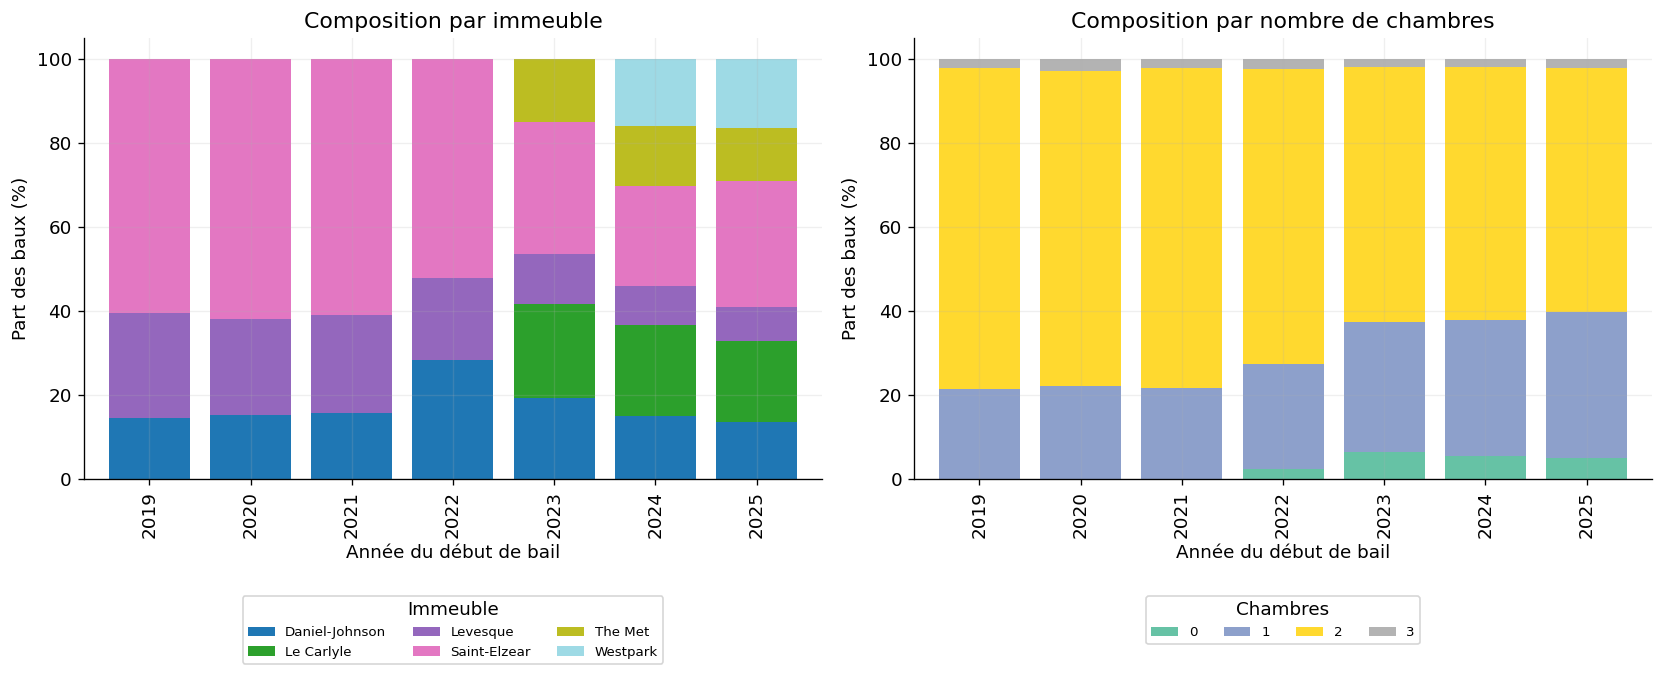

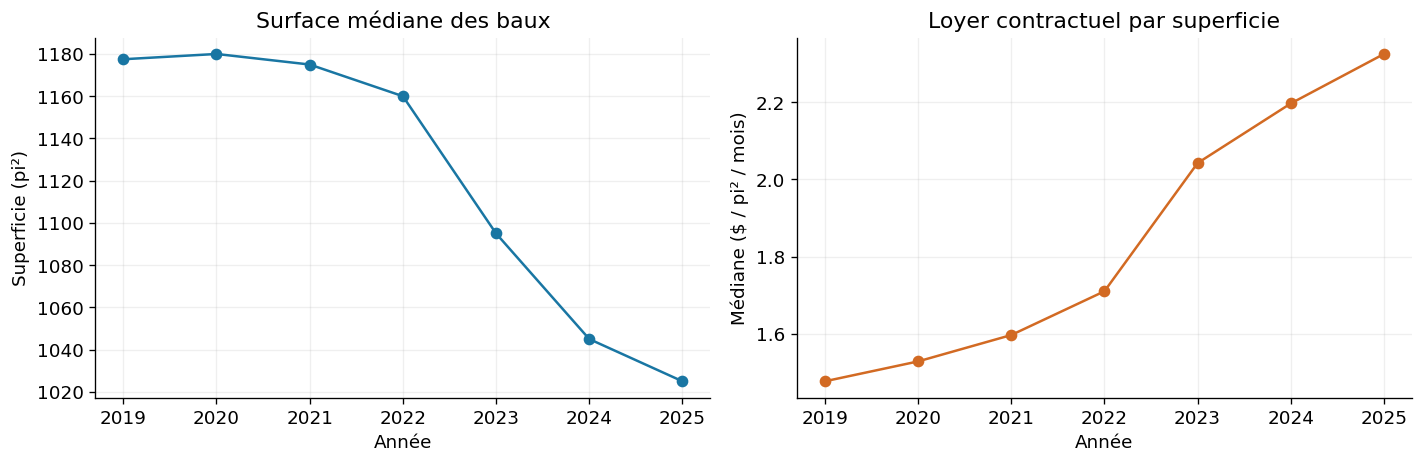

In [3]:
ANALYSIS_START_YEAR, LAST_OBSERVED_YEAR = 2019, 2025
window = leases.loc[leases.year.between(ANALYSIS_START_YEAR, LAST_OBSERVED_YEAR)].copy()
naive = window.groupby("year").agg(leases=("sRent", "size"), median_rent=("sRent", "median"))
naive["growth_pct"] = naive.median_rent.pct_change(fill_method=None) * 100
mix = window.assign(rent_per_sqft=window.sRent / window.sSqft).groupby("year").agg(
    leases=("sRent", "size"), median_sqft=("sSqft", "median"),
    two_plus_bed_share_pct=("sBeds", lambda values: values.ge(2).mean() * 100),
    median_rent_per_sqft=("rent_per_sqft", "median"), buildings=("sBuilding", "nunique"))
building_counts = pd.crosstab(window.year, window.sBuilding)
building_shares = building_counts.div(building_counts.sum(axis=1), axis=0) * 100
bedroom_counts = pd.crosstab(window.year, window.sBeds)
bedroom_shares = bedroom_counts.div(bedroom_counts.sum(axis=1), axis=0) * 100
display(naive.round(3))
display(mix.round(3))
display(building_counts)
display(building_shares.round(2))
display(bedroom_counts)
display(bedroom_shares.round(2))
display(leases.groupby("sBuilding").year.min().rename("first_observed_year").to_frame())

figure, axes = plt.subplots(1, 2, figsize=(14, 6))
building_shares.plot.bar(stacked=True, ax=axes[0], colormap="tab20", width=0.8)
axes[0].set(title="Composition par immeuble", xlabel="Année du début de bail", ylabel="Part des baux (%)")
axes[0].legend(title="Immeuble", fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=3)
bedroom_shares.plot.bar(stacked=True, ax=axes[1], colormap="Set2", width=0.8)
axes[1].set(title="Composition par nombre de chambres", xlabel="Année du début de bail", ylabel="Part des baux (%)")
axes[1].legend(title="Chambres", fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=4)
figure.tight_layout()
plt.show()

figure, axes = plt.subplots(1, 2, figsize=(12, 4))
mix.median_sqft.plot(marker="o", ax=axes[0], color=COLORS["contractual"])
axes[0].set(title="Surface médiane des baux", xlabel="Année", ylabel="Superficie (pi²)")
mix.median_rent_per_sqft.plot(marker="o", ax=axes[1], color=COLORS["effective"])
axes[1].set(title="Loyer contractuel par superficie", xlabel="Année", ylabel="Médiane ($ / pi² / mois)")
figure.tight_layout()
plt.show()

## 4. Comparer chaque appartement à lui-même — phase D

On trie sur la clé sûre et le début de bail, puis on décale d'une ligne les dates et **les deux prix**
dans chaque appartement. Les paires sont créées avant toute séparation renouvellement/relocation.
Des débuts identiques avec des valeurs contradictoires arrêtent le calcul; une suppression des doublons
exacts est comptabilisée. Les exclusions sont mutuellement exclusives et leur total doit égaler les entrées.

La fonction ci-dessous est la même implémentation que celle testée dans `equinoxe.py`.
Les valeurs limites, la longueur de l'année et les noms de colonnes sont configurés au chargement.

In [4]:
def consecutive_pairs(leases, min_gap=MIN_GAP_YEARS, max_gap=MAX_GAP_YEARS):
    validate_identity(leases)
    if leases["sLeaseFrom"].isna().any():
        raise ValueError("Missing lease start prevents reliable ordering.")
    if not leases["sRenewal"].isin([0, 1]).all():
        raise ValueError("Unknown renewal flag.")
    ordered = leases.drop_duplicates().sort_values(UNIT_KEY + ["sLeaseFrom"]).copy()
    if ordered.duplicated(UNIT_KEY + ["sLeaseFrom"]).any():
        raise ValueError("Ambiguous same-apartment lease start; resolve before pairing.")
    grouped = ordered.groupby(UNIT_KEY, observed=True)
    ordered["previous_date"] = grouped["sLeaseFrom"].shift()
    for column in PRICE_COLUMNS:
        ordered["previous_" + column] = grouped[column].shift()
    ordered["gap_years"] = (ordered["sLeaseFrom"] - ordered["previous_date"]).dt.days / DAYS_PER_YEAR
    has_previous = ordered["previous_date"].notna()
    interval_ok = ordered["gap_years"].gt(min_gap) & ordered["gap_years"].lt(max_gap)
    positive = ordered[PRICE_COLUMNS + ["previous_" + column for column in PRICE_COLUMNS]].gt(0).all(axis=1)
    positive &= ordered[PRICE_COLUMNS + ["previous_" + column for column in PRICE_COLUMNS]].notna().all(axis=1)
    eligible = has_previous & interval_ok & positive
    accounting = {
        "input_rows": len(leases), "exact_duplicates_removed": len(leases) - len(ordered),
        "first_leases": int((~has_previous).sum()),
        "short_intervals": int((has_previous & ordered["gap_years"].le(min_gap)).sum()),
        "long_intervals": int((has_previous & ordered["gap_years"].ge(max_gap)).sum()),
        "invalid_prices_after_interval": int((has_previous & interval_ok & ~positive).sum()),
        "eligible_pairs": int(eligible.sum()),
    }
    assert accounting["input_rows"] == sum(accounting[key] for key in accounting if key != "input_rows")
    pairs = ordered.loc[eligible].copy()
    pairs["year"] = pairs["sLeaseFrom"].dt.year
    for column in PRICE_COLUMNS:
        pairs[column + "_growth"] = (
            (pairs[column] / pairs["previous_" + column]) ** (1 / pairs["gap_years"]) - 1
        ) * 100
    return pairs, accounting, ordered.loc[has_previous & ~eligible].copy()

,count
input_rows,4302
exact_duplicates_removed,0
first_leases,1061
short_intervals,62
long_intervals,0
invalid_prices_after_interval,0
eligible_pairs,3179


,value
distinct_paired_apartments,890.000
extract_apartments,1061.000
paired_apartment_share_pct,83.883


,pairs,apartments,contractual_pct,effective_pct
year,,,,
2018,88,88,2.467,1.976
2019,159,159,2.142,1.629
2020,331,322,3.171,3.019
2021,355,355,4.457,3.543
2022,352,351,5.396,4.586
2023,416,416,2.288,2.019
2024,698,678,3.389,1.772
2025,780,779,7.045,3.575


,,excluded_transitions
sRenewal,gap_years,
0,0.498,16
1,0.498,46


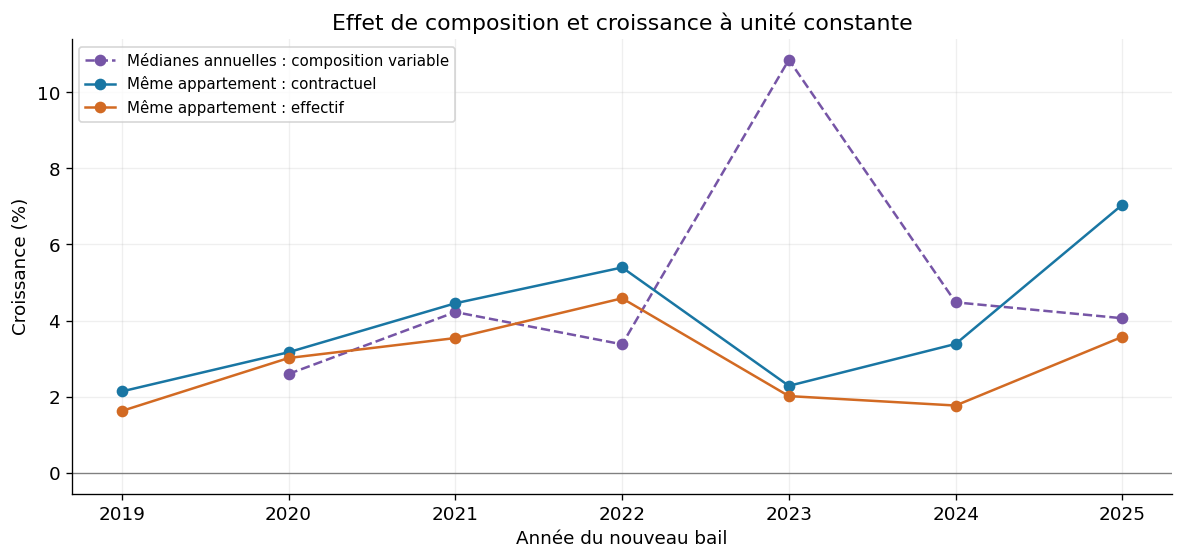

En 2023, la médiane annuelle augmente de **10.85 %**, contre **2.29 %** à appartement constant en contractuel et **2.02 %** en effectif. Une part accrue de baux d'immeubles plus chers peut augmenter la médiane globale sans hausse équivalente pour un logement donné. La différence entre ces statistiques ne constitue pas une décomposition causale exacte.

In [5]:
def same_unit_growth(df, price_col="sRent", min_gap=MIN_GAP_YEARS, max_gap=MAX_GAP_YEARS):
    pairs_result, accounting_result, excluded_result = consecutive_pairs(df, min_gap, max_gap)
    return pairs_result.assign(growth_pct=pairs_result[price_col + "_growth"])

pairs, pair_accounting, excluded = consecutive_pairs(leases)
display(pd.Series(pair_accounting).to_frame("count"))
display(pd.Series({"distinct_paired_apartments": pairs.groupby(UNIT_KEY).ngroups,
                   "extract_apartments": listings.hUnit.nunique(),
                   "paired_apartment_share_pct": pairs.hUnit.nunique() / listings.hUnit.nunique() * 100}).to_frame("value"))
annual_growth = pairs.groupby("year").agg(pairs=("hUnit", "size"),
    apartments=("hUnit", "nunique"), contractual_pct=("sRent_growth", "median"),
    effective_pct=("sRentEffective_growth", "median"))
display(annual_growth.round(4))
display(excluded.groupby(["sRenewal", "gap_years"]).size().rename("excluded_transitions").to_frame())

comparison = naive[["growth_pct"]].rename(columns={"growth_pct": "naive_contractual"}).join(
    annual_growth[["contractual_pct", "effective_pct"]])
figure, axis = plt.subplots()
for column, label, color, style in [
    ("naive_contractual", "Médianes annuelles : composition variable", COLORS["naive"], "--"),
    ("contractual_pct", "Même appartement : contractuel", COLORS["contractual"], "-"),
    ("effective_pct", "Même appartement : effectif", COLORS["effective"], "-"),
]:
    axis.plot(comparison.index, comparison[column], marker="o", linestyle=style, color=color, label=label)
axis.axhline(0, color="grey", linewidth=0.8)
axis.set(title="Effet de composition et croissance à unité constante", xlabel="Année du nouveau bail", ylabel="Croissance (%)")
axis.legend(fontsize=9)
figure.tight_layout()
plt.show()
display(Markdown(f"En 2023, la médiane annuelle augmente de **{naive.loc[2023, 'growth_pct']:.2f} %**, "
    f"contre **{annual_growth.loc[2023, 'contractual_pct']:.2f} %** à appartement constant en contractuel "
    f"et **{annual_growth.loc[2023, 'effective_pct']:.2f} %** en effectif. "
    "Une part accrue de baux d'immeubles plus chers peut augmenter la médiane globale sans hausse équivalente pour un logement donné. "
    "La différence entre ces statistiques ne constitue pas une décomposition causale exacte."))

### Sensibilité aux baux d'environ six mois

Les 62 exclusions courtes sont espacées de 182 jours : `182 / 365.25 ≈ 0.4983`, juste sous le seuil
du starter. Elles comprennent des renouvellements et des relocations, sans doublon exact démontré.
On conserve la cible stricte pour la comparaison officielle, puis on calcule une sensibilité descriptive
avec un seuil de 0.49. Cette variante n'est pas choisie pour améliorer le backtest et n'est pas mélangée
au résultat principal. L'annualisation d'une très courte transition amplifierait le bruit, ce qui motive le filtre.

In [6]:
SIX_MONTH_SENSITIVITY_MIN_GAP = 0.49
sensitivity_pairs, sensitivity_accounting, unused_excluded = consecutive_pairs(leases, min_gap=SIX_MONTH_SENSITIVITY_MIN_GAP)
sensitivity = annual_growth[["pairs", "effective_pct"]].rename(columns={"pairs": "strict_pairs", "effective_pct": "strict_effective_pct"}).join(
    sensitivity_pairs.groupby("year").agg(including_six_month_pairs=("hUnit", "size"),
        including_six_month_effective_pct=("sRentEffective_growth", "median")))
sensitivity["difference_pp"] = sensitivity.including_six_month_effective_pct - sensitivity.strict_effective_pct
display(sensitivity.round(4))

,strict_pairs,strict_effective_pct,including_six_month_pairs,including_six_month_effective_pct,difference_pp
year,,,,,
2018,88,1.976,93,2.058,0.082
2019,159,1.629,166,1.720,0.091
2020,331,3.019,334,3.030,0.010
2021,355,3.543,361,3.547,0.004
2022,352,4.586,359,4.609,0.022
2023,416,2.019,424,2.098,0.078
2024,698,1.772,706,1.865,0.094
2025,780,3.575,795,3.639,0.064


## 5. Concessions : prix contractuel et prix effectif — phase E

`sRentEffective` est notre mesure initiale, **sans la présenter comme une collecte de cash vérifiée**.
Le rabais de chaque bail est `100 × (1 - effectif / contractuel)`. Sa médiane diffère de la différence
entre les deux médianes de prix : on calcule les deux pour éviter une confusion.

PromoPay est un avantage promotionnel ponctuel, souvent d'un mois, de l'ordre d'un mois de loyer.
On ne soustrait pas son montant chaque mois du bail. Les codes sont tronqués et de casse variable :
`freerent` = loyer gratuit; `freepark` = stationnement; `freelock` = casier; `freeappl` = électroménagers;
`Indem` = indemnité; `Referenc` = référencement; `Freeothe` = divers; `PromoPay` = promotion.
La durée renseignée de 12 mois pour d'autres codes ne suffit pas à prouver que chaque montant est mensuel.

La table n'a pas de clé explicite de bail. On analyse ses montants/durées séparément, sans les attribuer
automatiquement à chaque bail de l'unité. Pas de reconstruction ni de réconciliation monétaire prétendument
exacte : cela risquerait les doubles comptes avec le loyer effectif fourni et les jointures plusieurs-à-plusieurs.

,leases,concession_share_pct,median_contractual,median_effective,median_per_lease_discount_pct,median_discount_cad,ratio_of_medians_discount_pct
year,,,,,,,
2017,93,38.710,1815.0,1800.000,0.000,0.00,0.826
2018,172,38.372,1610.0,1584.580,0.000,0.00,1.579
2019,328,44.207,1730.0,1694.835,0.000,0.00,2.033
2020,373,48.794,1775.0,1735.000,0.000,0.00,2.254
2021,361,54.017,1850.0,1785.000,4.086,48.40,3.514
2022,422,57.346,1912.5,1835.000,4.907,69.72,4.052
2023,693,54.257,2120.0,2025.400,5.410,71.23,4.462
2024,902,73.060,2215.0,2084.455,7.199,134.67,5.894
2025,958,85.386,2305.0,2105.590,10.305,219.92,8.651


leases  concession_share_pct  median_discount_pct
year sBuilding                                                        
2017 Saint-Elzear        93                38.710                0.000
2018 Levesque            64                37.500                0.000
     Saint-Elzear       108                38.889                0.000
2019 Daniel-Johnson      48                37.500                0.000
     Levesque            82                43.902                0.000
     Saint-Elzear       198                45.960                0.000
2020 Daniel-Johnson      57                28.070                0.000
     Levesque            85                57.647                3.691
     Saint-Elzear       231                50.649                3.316
2021 Daniel-Johnson      57                52.632                3.715
     Levesque            84                48.810                0.000
     Saint-Elzear       220                56.364                4.222
2022 Daniel-Johnson     120                52.500                4.661
     Levesque            82                59.756                4.826
     Saint-Elzear       220                59.091                5.079
2023 Daniel-Johnson     134                43.284                0.000
     Le Carlyle         155                59.355                5.600
     Levesque            83                48.193                0.000
     Saint-Elzear       217                52.074                5.484
     The Met            104                70.192                5.826
2024 Daniel-Johnson     136                64.706                7.329
     Le Carlyle         195                82.051                7.459
     Levesque            84                58.333                7.140
     Saint-Elzear       215                64.651                6.847
     The Met            128                82.812                7.192
     Westpark           144                81.250                7.433
2025 Daniel-Johnson     130                76.923               10.280
     Le Carlyle         185                92.973               10.652
     Levesque            77                83.117               10.157
     Saint-Elzear       288                75.000                9.789
     The Met            120                97.500               10.441
     Westpark           158                94.304               10.307

leases  concession_share_pct  median_discount_pct
year sRenewal                                                   
2017 0             91                38.462                0.000
     1              2                50.000                1.644
2018 0            121                36.364                0.000
     1             51                43.137                0.000
2019 0            231                42.424                0.000
     1             97                48.454                0.000
2020 0            172                50.000                1.635
     1            201                47.761                0.000
2021 0            136                54.412                4.002
     1            225                53.778                4.179
2022 0            190                54.211                4.659
     1            232                59.914                5.079
2023 0            447                57.942                5.583
     1            246                47.561                0.000
2024 0            474                77.215                7.307
     1            428                68.458                7.088
2025 0            475                82.105               10.107
     1            483                88.613               10.434

,records,median_amount_cad,median_months,min_months,max_months
sChargeCode,,,,,
Freeothe,570,-153.49,12.0,3.0,12.0
Indem,69,-149.26,12.0,3.0,17.0
PromoPay,1494,-1356.60,1.0,1.0,2.0
Referenc,36,-148.26,12.0,3.0,17.0
freeappl,44,-143.58,12.0,3.0,12.0
freelock,175,-139.35,12.0,3.0,12.0
freepark,1006,-150.50,12.0,3.0,23.0
freerent,166,-129.30,12.0,3.0,12.0


,PromoPay_records
sMonths,
1.0,1318
2.0,176


concession_records  median_signed_amount_cad
year sBuilding                                                   
2017 Saint-Elzear                    34                    -62.84
2018 Levesque                        23                    -53.02
     Saint-Elzear                    47                   -126.06
2019 Daniel-Johnson                  17                   -245.71
     Levesque                        43                    -57.66
     Saint-Elzear                    82                    -87.87
2020 Daniel-Johnson                  16                   -718.49
     Levesque                        62                   -124.37
     Saint-Elzear                   146                   -112.94
2021 Daniel-Johnson                  35                   -556.32
     Levesque                        58                   -135.78
     Saint-Elzear                   153                   -172.40
2022 Daniel-Johnson                  71                   -233.56
     Levesque                        67                   -138.34
     Saint-Elzear                   160                   -266.77
2023 Daniel-Johnson                  72                   -328.66
     Le Carlyle                      94                   -188.80
     Levesque                        52                   -177.00
     Saint-Elzear                   152                   -382.36
     The Met                         82                   -179.72
2024 Daniel-Johnson                 108                   -263.24
     Le Carlyle                     197                   -217.02
     Levesque                        61                   -192.70
     Saint-Elzear                   192                   -218.14
     The Met                        137                   -333.24
     Westpark                       111                   -215.95
2025 Daniel-Johnson                 114                   -468.49
     Le Carlyle                     213                   -498.70
     Levesque                        64                   -260.05
     Saint-Elzear                   243                   -439.06
     The Met                        153                   -632.72
     Westpark                       185                   -351.31
2026 Daniel-Johnson                  43                  -1535.00
     Le Carlyle                      61                  -1695.36
     Levesque                        42                   -987.50
     Saint-Elzear                    74                  -1721.01
     The Met                         39                  -1670.05
     Westpark                        55                  -1373.84
2027 Daniel-Johnson                   1                  -3739.63
     Saint-Elzear                     1                  -2958.82

,count
negative_amount_records,3560
concession_end_dates_after_2025,746
flag_zero_but_discount_positive,0
flag_one_but_discount_zero,0


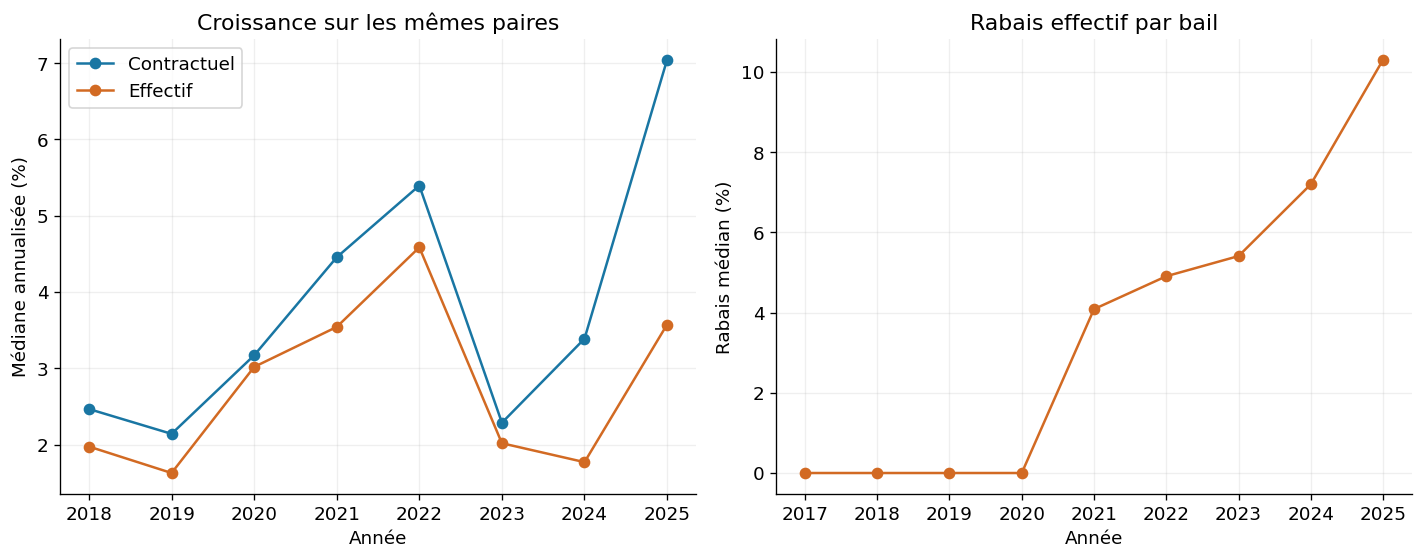

En 2025 : **7.04 % contractuel** et **3.58 % effectif**. La divergence est compatible avec des avantages plus importants : un prix au bail plus élevé ne garantit pas le même gain net. Ces agrégats seuls ne permettent pas d'attribuer causalement toute la différence aux concessions.

In [7]:
lease_discounts = leases.assign(discount_pct=(1 - leases.sRentEffective / leases.sRent) * 100,
                                discount_cad=leases.sRent - leases.sRentEffective)
discount_year = lease_discounts.groupby("year").agg(leases=("sRent", "size"),
    concession_share_pct=("sConcession", lambda values: values.mean() * 100),
    median_contractual=("sRent", "median"), median_effective=("sRentEffective", "median"),
    median_per_lease_discount_pct=("discount_pct", "median"), median_discount_cad=("discount_cad", "median"))
discount_year["ratio_of_medians_discount_pct"] = (1 - discount_year.median_effective / discount_year.median_contractual) * 100
display(discount_year.round(3))
display(lease_discounts.groupby(["year", "sBuilding"]).agg(leases=("sRent", "size"),
    concession_share_pct=("sConcession", lambda values: values.mean() * 100),
    median_discount_pct=("discount_pct", "median")).round(3))
display(lease_discounts.groupby(["year", "sRenewal"]).agg(leases=("sRent", "size"),
    concession_share_pct=("sConcession", lambda values: values.mean() * 100),
    median_discount_pct=("discount_pct", "median")).round(3))
concession_types = concessions.groupby("sChargeCode").agg(records=("sAmount", "size"),
    median_amount_cad=("sAmount", "median"), median_months=("sMonths", "median"),
    min_months=("sMonths", "min"), max_months=("sMonths", "max"))
display(concession_types.round(2))
display(concessions.loc[concessions.sChargeCode.eq("PromoPay")].groupby("sMonths").size().rename("PromoPay_records").to_frame())
display(concessions.assign(year=concessions.sDateFrom.dt.year).groupby(["year", "sBuilding"]).agg(
    concession_records=("sAmount", "size"), median_signed_amount_cad=("sAmount", "median")).round(2))
display(pd.Series({"negative_amount_records": int(concessions.sAmount.lt(0).sum()),
    "concession_end_dates_after_2025": int(concessions.sDateTo.gt(pd.Timestamp("2025-12-31")).sum()),
    "flag_zero_but_discount_positive": int((lease_discounts.sConcession.eq(0) & lease_discounts.discount_pct.gt(0)).sum()),
    "flag_one_but_discount_zero": int((lease_discounts.sConcession.eq(1) & lease_discounts.discount_pct.eq(0)).sum())}).to_frame("count"))

figure, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for column, color, label in [("contractual_pct", COLORS["contractual"], "Contractuel"),
                             ("effective_pct", COLORS["effective"], "Effectif")]:
    axes[0].plot(annual_growth.index, annual_growth[column], marker="o", color=color, label=label)
axes[0].set(title="Croissance sur les mêmes paires", xlabel="Année", ylabel="Médiane annualisée (%)")
axes[0].legend()
axes[1].plot(discount_year.index, discount_year.median_per_lease_discount_pct, marker="o", color=COLORS["effective"])
axes[1].set(title="Rabais effectif par bail", xlabel="Année", ylabel="Rabais médian (%)")
figure.tight_layout()
plt.show()
display(Markdown(f"En 2025 : **{annual_growth.loc[2025, 'contractual_pct']:.2f} % contractuel** et "
    f"**{annual_growth.loc[2025, 'effective_pct']:.2f} % effectif**. "
    "La divergence est compatible avec des avantages plus importants : un prix au bail plus élevé ne garantit pas le même gain net. "
    "Ces agrégats seuls ne permettent pas d'attribuer causalement toute la différence aux concessions."))

## 6. Renouvellements, relocations et loyers affichés — phase F

La classification vient du **nouveau** bail, après appariement. Un locataire qui renouvelle et une
unité relouée ne répondent pas aux mêmes mécanismes de marché. On affiche nombres de paires et
croissances par année/type/province. Les faibles effectifs ne donnent pas un taux représentatif à eux seuls.

L'historique des prix affichés est irrégulier : ni panel mensuel complet ni loyer signé. Aucun mois manquant
n'est remplacé par zéro. Le dernier prix affiché connu à chaque cutoff peut être ancien; sa staleness
est calculée en jours depuis le premier jour du mois renseigné. La date de publication CRM du relevé
n'est pas fournie : disponibilité au mois indiqué est une hypothèse de diagnostic, pas un prédicteur utilisé.
Les prix courants des listings sont exclus des modèles et des backtests.

pairs  contractual_pct  effective_pct
year sRenewal                                       
2018 0            41            1.026          1.026
     1            47            2.999          2.657
2019 0            67            1.212          1.324
     1            92            2.552          1.958
2020 0           131            2.047          2.321
     1           200            3.429          3.284
2021 0           135            3.516          2.356
     1           220            4.772          4.002
2022 0           126            4.216          3.402
     1           226            5.687          4.924
2023 0           177            1.851          1.685
     1           239            2.578          2.214
2024 0           276            4.855          2.747
     1           422            2.943          1.381
2025 0           307            8.981          5.741
     1           473            6.409          2.908

pairs  contractual_pct  effective_pct
year sState  sRenewal                                       
2018 Quebec  0            41            1.026          1.026
             1            47            2.999          2.657
2019 Quebec  0            67            1.212          1.324
             1            92            2.552          1.958
2020 Quebec  0           131            2.047          2.321
             1           200            3.429          3.284
2021 Quebec  0           135            3.516          2.356
             1           220            4.772          4.002
2022 Quebec  0           126            4.216          3.402
             1           226            5.687          4.924
2023 Quebec  0           177            1.851          1.685
             1           239            2.578          2.214
2024 Ontario 0            41            4.939          3.213
             1            67            2.974          1.334
     Quebec  0           235            4.839          2.519
             1           355            2.943          1.396
2025 Ontario 0            54            8.960          5.448
             1            63            6.245          2.458
     Quebec  0           253            8.981          5.804
             1           410            6.435          2.972

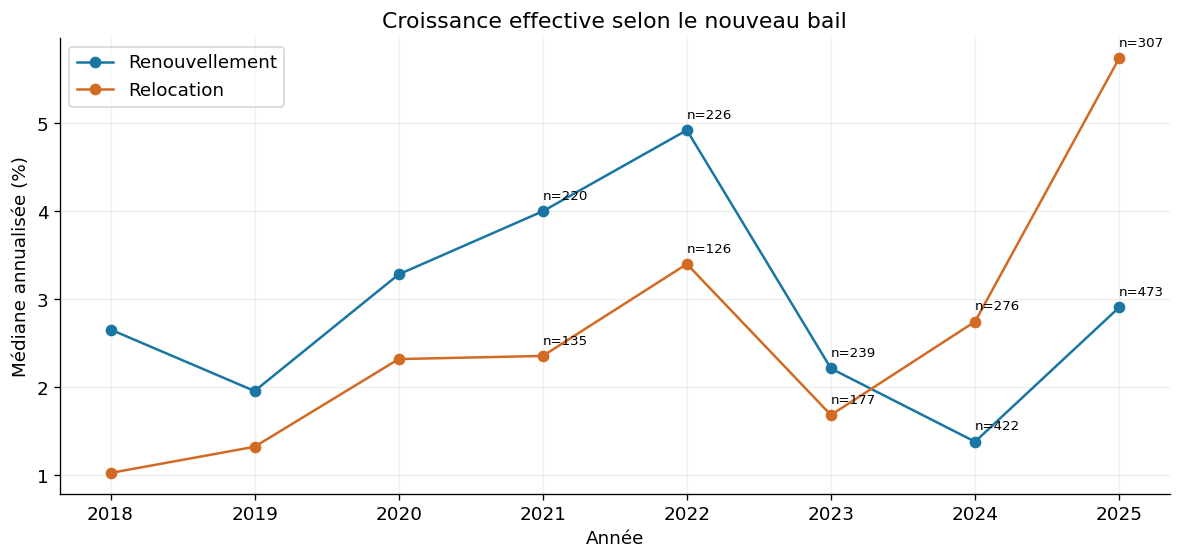

,value
observations,3857
apartments,1061
mean_observations_per_apartment,3.635
maximum_observations,12
first_month,2016-10
last_month,2025-12


,cutoff_year,units_with_prior_asking,median_age_days,p90_age_days,older_than_one_year_share_pct
0,2022,466,244.0,744.5,29.83
1,2023,720,244.0,639.0,23.61
2,2024,912,244.0,671.0,30.92
3,2025,1061,305.0,791.0,39.30


In [8]:
type_growth = pairs.groupby(["year", "sRenewal"]).agg(pairs=("hUnit", "size"),
    contractual_pct=("sRent_growth", "median"), effective_pct=("sRentEffective_growth", "median"))
province_type_growth = pairs.groupby(["year", "sState", "sRenewal"]).agg(pairs=("hUnit", "size"),
    contractual_pct=("sRent_growth", "median"), effective_pct=("sRentEffective_growth", "median"))
display(type_growth.round(4))
display(province_type_growth.round(4))
figure, axis = plt.subplots()
for renewal, label, color in [(1, "Renouvellement", COLORS["contractual"]), (0, "Relocation", COLORS["effective"])]:
    selected = type_growth.xs(renewal, level="sRenewal")
    axis.plot(selected.index, selected.effective_pct, marker="o", color=color, label=label)
    for year, row in selected.loc[selected.index >= 2021].iterrows():
        axis.annotate(f"n={int(row.pairs)}", (year, row.effective_pct), xytext=(0, 7), textcoords="offset points", fontsize=8)
axis.set(title="Croissance effective selon le nouveau bail", xlabel="Année", ylabel="Médiane annualisée (%)")
axis.legend()
figure.tight_layout()
plt.show()

asking_counts = asking.groupby(UNIT_KEY).size()
display(pd.Series({"observations": len(asking), "apartments": len(asking_counts),
    "mean_observations_per_apartment": asking_counts.mean(), "maximum_observations": asking_counts.max(),
    "first_month": asking.date.min().strftime("%Y-%m"), "last_month": asking.date.max().strftime("%Y-%m")}).to_frame("value"))
asking_cutoffs = []
for cutoff_year in [2022, 2023, 2024, 2025]:
    snapshot = latest_asking(asking, pd.Timestamp(cutoff_year, 12, 31))
    asking_cutoffs.append({"cutoff_year": cutoff_year, "units_with_prior_asking": len(snapshot),
        "median_age_days": snapshot.age_days.median(), "p90_age_days": snapshot.age_days.quantile(0.9),
        "older_than_one_year_share_pct": snapshot.age_days.gt(DAYS_PER_YEAR).mean() * 100})
display(pd.DataFrame(asking_cutoffs).round(2))

## 7. Information publique datée et cadre provincial — phase G

Les valeurs publiques transcrites sont chargées depuis `docs/public_signals.json`. Chaque ligne comporte
géographie, variable, unité, période et date de publication. La bibliographie détaillée donne les URL,
éditeurs, date de consultation (2026-10-03), limites et usages. Ce tableau est un fichier public versionné,
donc l'exécution ne dépend pas d'un téléchargement en direct.

On simule le 31 décembre 2025. Le rapport SCHL 2025 était publié le 11 décembre; l'IPC de décembre
2025 ne l'était que le 19 janvier 2026 et est exclu. Le rapport SCHL 2023 publié le 31 janvier 2024
n'était pas disponible pour prévoir 2024 au 31 décembre 2023. Les séries historiques complètes par
vintage ne sont pas assemblées : **les backtests utilisent les données internes seules**, sans coefficient
extérieur prétendument validé. Les statistiques extérieures sont intégrées comme contexte et diagnostics datés.

La SCHL observe un marché qui se détend : inoccupation 2025 de 2.9 % à Montréal et 3.0 % à Ottawa.
Les loyers moyens deux chambres ($1 346 et $1 926) et leur croissance (7.2 % et 3.4 %) ne sont pas notre
médiane de transitions annualisées, et ne mesurent pas identiquement les concessions. L'IPC loyers de
septembre 2025 distingue Québec (9.6 %) et Ontario (3.5 %); ces lectures provinciales sont volontairement
datées, pas présentées comme les plus récentes. L'IPC loyers national ralentit à 4.7 % en novembre.
Ces signaux peuvent coexister avec une progression effective plus modérée dans l'extrait.

**Ontario :** la ligne directrice 2026 de 2.1 %, annoncée le 30 juin 2025, comporte notamment une exemption
pour la première occupation résidentielle après le 15 novembre 2018 et ne plafonne pas le prix d'une unité
vacante lors de la nouvelle location. Les premières observations de The Met sont récentes, mais ne prouvent
pas sa première occupation légale. Son assujettissement exact reste à vérifier; aucun plafonnement automatique.

**Québec :** les calculs TAL sont conditionnels, pas un plafond universel. Les immeubles construits/changés
d'affectation depuis cinq ans ou moins peuvent relever de restrictions à la fixation, selon la section F
et les conditions du bail, avec exigences supplémentaires pour certains bâtiments/baux après février 2024.
La réforme annoncée le 17 décembre 2025 utilise notamment une moyenne de l'IPC **général** sur trois ans
pour les avis concernés dès 2026. L'IPC général n'est pas l'IPC loyers. Le taux numérique publié en janvier
2026 n'entre pas dans notre information. Dates officielles, avis, charges et section F sont absents : impossible
d'en déduire une hausse légalement admissible par appartement. Les pages TAL actuelles servent à vérifier
les conditions, pas à fabriquer un vintage historique.

In [9]:
external = pd.DataFrame(json.loads((ROOT / "docs" / "public_signals.json").read_text(encoding="utf-8")))
external_at_cutoff = available_external(external, "2025-12-31")
display(external_at_cutoff)
display(pd.DataFrame([{"forecast_year": year, "external_rows_available": len(available_external(external, pd.Timestamp(year - 1, 12, 31)))}
                      for year in [2023, 2024, 2025, 2026]]))

,source_id,geography,variable,value,unit,reference_end,published_at
0,cmhc_2025,Montreal CMA,purpose_built_vacancy,2.9,percent,2025-10-31,2025-12-11
1,cmhc_2025,Ottawa CMA (Ontario),purpose_built_vacancy,3.0,percent,2025-10-31,2025-12-11
2,cmhc_2025,Montreal CMA,average_two_bedroom_rent,1346.0,CAD/month,2025-10-31,2025-12-11
3,cmhc_2025,Ottawa CMA (Ontario),average_two_bedroom_rent,1926.0,CAD/month,2025-10-31,2025-12-11
4,cmhc_2025,Montreal CMA,two_bedroom_rent_growth,7.2,percent_yoy,2025-10-31,2025-12-11
5,cmhc_2025,Ottawa CMA (Ontario),two_bedroom_rent_growth,3.4,percent_yoy,2025-10-31,2025-12-11
6,statcan_september_2025,Quebec,rent_cpi_yoy,9.6,percent_yoy,2025-09-30,2025-10-21
7,statcan_september_2025,Ontario,rent_cpi_yoy,3.5,percent_yoy,2025-09-30,2025-10-21
8,statcan_november_2025,Canada,rent_cpi_yoy,4.7,percent_yoy,2025-11-30,2025-12-15
9,ontario_2026,Ontario,conditional_renewal_guideline,2.1,percent,2026-12-31,2025-06-30


,forecast_year,external_rows_available
0,2023,0
1,2024,0
2,2025,0
3,2026,10


## 8. Trois méthodes prédéclarées, une logique temporelle — phases H et I

1. **Année précédente** : médiane globale observée en année précédente.
2. **Moyenne récente** : moyenne arithmétique des médianes globales des trois années précédentes.
   On donne un poids égal aux années, pas aux nombres de baux. Trois ans limitent la dépendance à un seul
   millésime sans extrapoler loin dans un régime ancien. Si moins d'années existent, le diagnostic le montre;
   sans aucune paire récente, le calcul s'arrête.
3. **Distribution segmentée** : un seul essai d'amélioration, par province et type. Dans les groupes
   suffisamment documentés (30 paires/an dans au moins deux années), on donne un poids égal aux
   distributions annuelles, puis les parts des groupes viennent des paires de l'année précédente seulement.
   On calcule la médiane du mélange pondéré de **toutes ces valeurs**, pas la moyenne des médianes de groupes.
   Un groupe récent insuffisant reçoit la référence globale. Un groupe absent à la coupure ne reçoit pas un
   poids futur inventé; s'il apparaît en 2026, cette hypothèse de composition peut échouer.

Toutes prédisent la **même cible observée non pondérée**. La pondération du candidat est une hypothèse sur
la distribution future, pas un changement de cible en indice à composition fixe. Pas de recherche massive
d'hyperparamètres, de XGBoost ou de coefficients externes arbitraires.

Pour prévoir l'année Y : on retient les baux dont début **et signature** sont au plus tard le 31 décembre Y−1,
puis on construit leurs paires. Un bail signé avant la coupure mais commençant après est exclu par choix
conservateur. Les prix affichés sont filtrés au même cutoff pour les diagnostics seulement. Les sources publiques
sont filtrées sur la publication, ce qui conserve à juste titre une règle future déjà annoncée.

In [10]:
def forecast(leases, target_year, method="recent_mean", price_col="sRentEffective", asking=None, external=None):
    if method not in METHODS or price_col not in PRICE_COLUMNS:
        raise ValueError("Unknown forecast method or price variable.")
    cutoff = pd.Timestamp(target_year - 1, 12, 31)
    history = known_leases(leases, cutoff)
    pairs, accounting, unused_excluded = consecutive_pairs(history)
    growth_col = price_col + "_growth"
    annual = pairs.groupby("year")[growth_col].median()
    recent = annual.reindex(range(target_year - HISTORY_YEARS, target_year)).dropna()
    if recent.empty:
        raise ValueError("No eligible recent history available before cutoff.")
    baseline = float(recent.mean())
    groups = []
    if method == "previous_year":
        if target_year - 1 not in annual:
            raise ValueError("Previous-year baseline has no previous-year observations.")
        prediction = float(annual.loc[target_year - 1])
    elif method == "recent_mean":
        prediction = baseline
    else:
        current = pairs.loc[pairs["year"].eq(target_year - 1)]
        if current.empty:
            raise ValueError("No previous-year pairs for composition weights.")
        recent_pairs = pairs.loc[pairs["year"].between(target_year - HISTORY_YEARS, target_year - 1)]
        values = []
        weights = []
        group_columns = ["sState", "sRenewal"]
        for key, current_group in current.groupby(group_columns, observed=True):
            pool = recent_pairs.loc[recent_pairs["sState"].eq(key[0]) & recent_pairs["sRenewal"].eq(key[1])]
            counts = pool.groupby("year").size()
            valid_years = counts.loc[counts.ge(MIN_GROUP_PAIRS)].index
            supported = len(valid_years) >= MIN_GROUP_YEARS
            group_weight = len(current_group) / len(current)
            if supported:
                for year in valid_years:
                    year_pool = pool.loc[pool["year"].eq(year), growth_col]
                    values.extend(year_pool.tolist())
                    weights.extend([group_weight / len(valid_years) / len(year_pool)] * len(year_pool))
            else:
                values.append(baseline)
                weights.append(group_weight)
            groups.append({"province": key[0], "renewal": int(key[1]), "weight": group_weight,
                           "supported_years": len(valid_years), "fallback": not supported})
        prediction = weighted_median(values, weights)
    signals = available_external(external, cutoff)
    asking_snapshot = latest_asking(asking, cutoff)
    return {
        "target_year": target_year, "cutoff": cutoff.date().isoformat(), "method": method,
        "price_col": price_col, "prediction_pct": prediction, "training_leases": len(history),
        "training_pairs": len(pairs), "annual_history": recent.to_dict(), "exclusion_accounting": accounting,
        "groups": groups, "available_external_rows": len(signals),
        "asking_units_at_cutoff": len(asking_snapshot),
        "asking_median_age_days": float(asking_snapshot["age_days"].median()) if len(asking_snapshot) else None,
    }

### Comparer prévision et réalisation sans changer d'agrégat

Le calcul de réalisation utilise les baux connus à la fin de Y, construit les prédécesseurs sur tout
l'historique admissible, puis sélectionne les transitions débutant en Y. Le bail antérieur peut donc venir
d'une année précédente. L'erreur signée est `prévision - observation`; l'erreur absolue et la MAE sont
en **points de pourcentage**, pas une « précision de classification ».

In [11]:
def evaluate(leases, target_year, method="recent_mean", price_col="sRentEffective", asking=None, external=None):
    result = forecast(leases, target_year, method, price_col, asking, external)
    observed_leases = known_leases(leases, pd.Timestamp(target_year, 12, 31))
    observed_pairs, unused_accounting, unused_excluded = consecutive_pairs(observed_leases)
    target = observed_pairs.loc[observed_pairs["year"].eq(target_year)]
    if target.empty:
        raise ValueError("No observed target-year pairs.")
    observed = float(target[price_col + "_growth"].median())
    result.update({"observed_pct": observed, "error_pp": result["prediction_pct"] - observed,
                   "absolute_error_pp": abs(result["prediction_pct"] - observed),
                   "observed_pairs": len(target), "observed_units": target.groupby(UNIT_KEY).ngroups})
    return result

In [12]:
DEVELOPMENT_YEARS = (2023, 2024, 2025)
development_rows = []
for method in METHODS:
    for year in DEVELOPMENT_YEARS:
        detail = evaluate(leases, year, method=method, asking=asking, external=external)
        development_rows.append({key: detail[key] for key in ["method", "target_year", "prediction_pct", "observed_pct",
            "error_pp", "absolute_error_pp", "training_leases", "training_pairs", "observed_pairs", "observed_units",
            "available_external_rows"]})
development = pd.DataFrame(development_rows)
method_scores = development.groupby("method").absolute_error_pp.mean().rename("mae_pp").sort_values().to_frame()
display(development.round(4))
display(method_scores.round(4))

,method,target_year,prediction_pct,observed_pct,error_pp,absolute_error_pp,training_leases,training_pairs,observed_pairs,observed_units,available_external_rows
0,previous_year,2023,4.586,2.019,2.567,2.567,1749,1285,416,416,0
1,previous_year,2024,2.019,1.772,0.248,0.248,2442,1701,698,678,0
2,previous_year,2025,1.772,3.575,-1.804,1.804,3344,2399,780,779,0
3,recent_mean,2023,3.716,2.019,1.697,1.697,1749,1285,416,416,0
4,recent_mean,2024,3.383,1.772,1.611,1.611,2442,1701,698,678,0
5,recent_mean,2025,2.792,3.575,-0.783,0.783,3344,2399,780,779,0
6,segmented_distribution,2023,3.646,2.019,1.627,1.627,1749,1285,416,416,0
7,segmented_distribution,2024,3.228,1.772,1.456,1.456,2442,1701,698,678,0
8,segmented_distribution,2025,2.792,3.575,-0.783,0.783,3344,2399,780,779,0


,mae_pp
method,
segmented_distribution,1.289
recent_mean,1.364
previous_year,1.540


### Choix du modèle et limites de la validation

On retient **la moyenne récente** pour la prévision centrale. Le gain du mélange segmenté est faible
sur seulement trois années; il ajoute des seuils et une hypothèse de stabilité des parts. Cette comparaison
ne suffit pas à conclure qu'il généralise mieux. Le choix privilégie une méthode facile à reproduire et
à expliquer, tout en conservant les résultats du candidat. Les seuils et la fenêtre n'ont pas été ajustés
pour chercher le meilleur score.

Ces trois années servent à comparer et expliquer les méthodes : **backtests de développement**, pas
ensemble indépendant de test. Les prévisions individuelles respectent le cutoff, mais notre décision de
méthode intervient après examen des trois résultats. L'extrait actuel ne fournit pas de versions anciennes
du CRM; on suppose que les données historiques n'ont pas été révisées depuis. Les résultats futurs peuvent
être différents, notamment pour les immeubles récents et les changements de politique de concessions.

,target_year,cutoff,prediction_pct,observed_pct,error_pp,absolute_error_pp,observed_pairs,observed_units
0,2023,2022-12-31,3.716,2.019,1.697,1.697,416,416
1,2024,2023-12-31,3.383,1.772,1.611,1.611,698,678
2,2025,2024-12-31,2.792,3.575,-0.783,0.783,780,779


MAE de développement du modèle retenu : **1.364 points de pourcentage**.

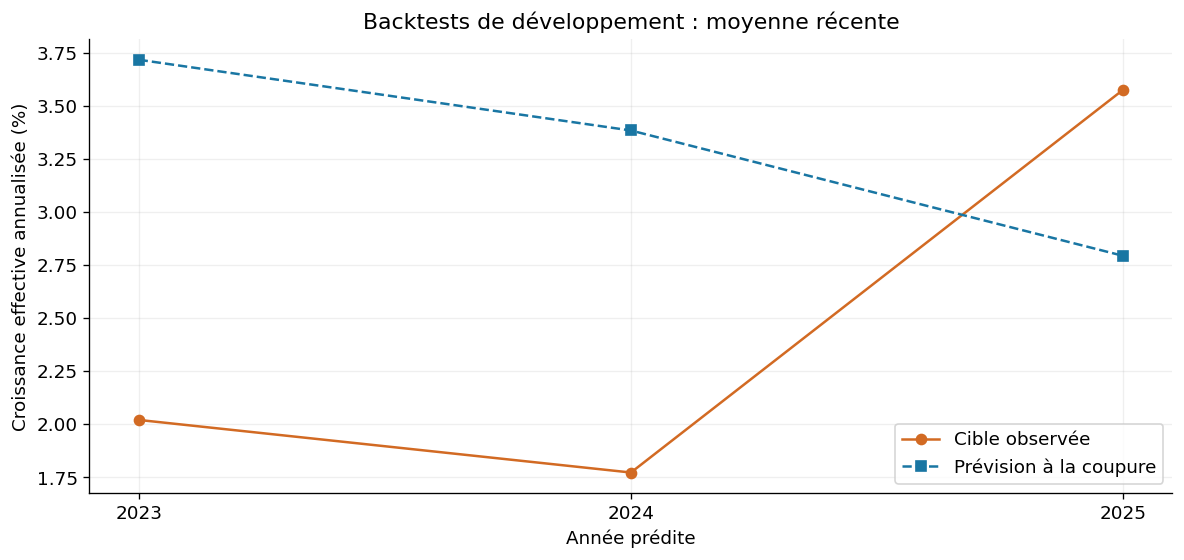

In [13]:
SELECTED_METHOD = "recent_mean"
forecast_diagnostics = {}

def estimate_2026(leases, asking, external=None, method=SELECTED_METHOD):
    detail = forecast(leases, 2026, method=method, asking=asking, external=external)
    forecast_diagnostics.clear()
    forecast_diagnostics.update(detail)
    return float(detail["prediction_pct"])

def backtest(leases, target_year, method=SELECTED_METHOD, asking=None, external=None):
    return evaluate(leases, target_year, method=method, asking=asking, external=external)

selected_validation = pd.DataFrame([
    {key: value for key, value in backtest(leases, year, asking=asking, external=external).items()
     if key in ["target_year", "cutoff", "prediction_pct", "observed_pct", "error_pp", "absolute_error_pp", "observed_pairs", "observed_units"]}
    for year in DEVELOPMENT_YEARS
])
display(selected_validation.round(4))
selected_mae = float(selected_validation.absolute_error_pp.mean())
display(Markdown(f"MAE de développement du modèle retenu : **{selected_mae:.3f} points de pourcentage**."))
figure, axis = plt.subplots()
axis.plot(selected_validation.target_year, selected_validation.observed_pct, "o-", color=COLORS["effective"], label="Cible observée")
axis.plot(selected_validation.target_year, selected_validation.prediction_pct, "s--", color=COLORS["contractual"], label="Prévision à la coupure")
axis.set(title="Backtests de développement : moyenne récente", xlabel="Année prédite", ylabel="Croissance effective annualisée (%)", xticks=DEVELOPMENT_YEARS)
axis.legend()
figure.tight_layout()
plt.show()

## 9. Prévision 2026 et sous-groupes — phase J

Les prévisions par type/province/immeuble ci-dessous utilisent la même idée de moyenne des médianes
annuelles, avec seuil de soutien et repli explicite. Elles sont des diagnostics distincts; leur moyenne
pondérée n'est pas la médiane globale et ne sert pas à la reconstituer. Westpark, à histoire courte,
peut recevoir un repli : ce n'est pas une validation spécifique de cet immeuble. Aucun poids de
composition 2026 ni prix futur n'est utilisé.

In [14]:
def group_forecasts(leases, target_year, group_columns, price_col="sRentEffective", requested_groups=None):
    cutoff = pd.Timestamp(target_year - 1, 12, 31)
    history = known_leases(leases, cutoff)
    pairs, unused_accounting, unused_excluded = consecutive_pairs(history)
    recent_pairs = pairs.loc[pairs["year"].between(target_year - HISTORY_YEARS, target_year - 1)]
    baseline = forecast(leases, target_year, price_col=price_col)["prediction_pct"]
    records = []
    group_keys = history[group_columns].drop_duplicates()
    if requested_groups is not None:
        requested = pd.DataFrame(requested_groups)
        if not set(group_columns).issubset(requested):
            raise ValueError("Requested groups must provide all grouping columns.")
        group_keys = pd.concat([group_keys, requested[group_columns]], ignore_index=True).drop_duplicates()
    for key in group_keys.itertuples(index=False, name=None):
        mask = pd.Series(True, index=recent_pairs.index)
        for column, value in zip(group_columns, key):
            mask &= recent_pairs[column].eq(value)
        pool = recent_pairs.loc[mask]
        counts = pool.groupby("year").size()
        supported_years = counts.loc[counts.ge(MIN_GROUP_PAIRS)].index
        medians = pool.groupby("year")[price_col + "_growth"].median().reindex(supported_years)
        supported = len(supported_years) >= MIN_GROUP_YEARS
        records.append(dict(zip(group_columns, key), prediction_pct=float(medians.mean()) if supported else baseline,
                            recent_pairs=len(pool), supported_years=len(supported_years), fallback=not supported))
    return pd.DataFrame(records)

In [15]:
effective_forecast = estimate_2026(leases, asking, external)
contractual_forecast = forecast(leases, 2026, method=SELECTED_METHOD, price_col="sRent")["prediction_pct"]
type_forecast = group_forecasts(leases, 2026, ["sRenewal"])
province_forecast = group_forecasts(leases, 2026, ["sState", "sRenewal"])
building_forecast = group_forecasts(leases, 2026, ["sBuilding"])
for grouping, result in [(["sRenewal"], type_forecast), (["sState", "sRenewal"], province_forecast), (["sBuilding"], building_forecast)]:
    contractual_groups = group_forecasts(leases, 2026, grouping, price_col="sRent").rename(columns={"prediction_pct": "contractual_prediction_pct"})
    joined = result.merge(contractual_groups[grouping + ["contractual_prediction_pct"]], on=grouping, validate="one_to_one")
    display(joined.round(4))
display(pd.Series({key: value for key, value in forecast_diagnostics.items()
    if key in ["target_year", "cutoff", "method", "prediction_pct", "training_leases", "training_pairs", "available_external_rows",
               "asking_units_at_cutoff", "asking_median_age_days"]}).to_frame("diagnostic"))
display(Markdown(f"### Prévision centrale 2026 : **{effective_forecast:.2f} %**\n\n"
    "Cible : médiane non pondérée de la croissance annualisée du loyer effectif sur les transitions admissibles "
    f"de baux consécutifs du même appartement commençant en 2026. Comparaison contractuelle : **{contractual_forecast:.2f} %**. "
    "Il s'agit d'une prévision de variation de prix des transitions représentées, pas d'une hausse exacte du revenu total."))

recent_realizations = annual_growth.loc[2026 - HISTORY_YEARS:2025, "effective_pct"]
scenarios = pd.DataFrame([
    {"scenario": "Bas : retour au régime récent le plus faible", "effective_growth_pct": recent_realizations.min()},
    {"scenario": "Central : moyenne des trois régimes récents", "effective_growth_pct": effective_forecast},
    {"scenario": "Haut : persistance du régime récent le plus fort", "effective_growth_pct": recent_realizations.max()},
])
display(scenarios.round(3))
six_month_recent_mean = float(sensitivity.loc[2023:2025, "including_six_month_effective_pct"].mean())
display(Markdown(f"Sensibilité descriptive aux intervalles de 182 jours : référence trois ans **{six_month_recent_mean:.2f} %**, "
    f"soit **{six_month_recent_mean - effective_forecast:+.3f} point** par rapport à la cible stricte."))

,sRenewal,prediction_pct,recent_pairs,supported_years,fallback,contractual_prediction_pct
0,0,3.391,760,3,False,5.229
1,1,2.168,1134,3,False,3.977


,sState,sRenewal,prediction_pct,recent_pairs,supported_years,fallback,contractual_prediction_pct
0,Quebec,0,3.336,665,3,False,5.223
1,Quebec,1,2.194,1004,3,False,3.985
2,Ontario,0,4.331,95,2,False,6.950
3,Ontario,1,1.896,130,2,False,4.610


,sBuilding,prediction_pct,recent_pairs,supported_years,fallback,contractual_prediction_pct
0,Le Carlyle,2.616,339,2,False,5.068
1,Daniel-Johnson,2.687,381,3,False,4.301
2,Levesque,2.607,240,3,False,4.255
3,The Met,2.640,225,2,False,5.117
4,Saint-Elzear,2.406,575,3,False,4.260
5,Westpark,2.455,134,1,True,4.241


,diagnostic
target_year,2026
cutoff,2025-12-31
method,recent_mean
prediction_pct,2.455
training_leases,4302
training_pairs,3179
available_external_rows,10
asking_units_at_cutoff,1061
asking_median_age_days,305.0


### Prévision centrale 2026 : **2.46 %**

Cible : médiane non pondérée de la croissance annualisée du loyer effectif sur les transitions admissibles de baux consécutifs du même appartement commençant en 2026. Comparaison contractuelle : **4.24 %**. Il s'agit d'une prévision de variation de prix des transitions représentées, pas d'une hausse exacte du revenu total.

,scenario,effective_growth_pct
0,Bas : retour au régime récent le plus faible,1.772
1,Central : moyenne des trois régimes récents,2.455
2,Haut : persistance du régime récent le plus fort,3.575


Sensibilité descriptive aux intervalles de 182 jours : référence trois ans **2.53 %**, soit **+0.079 point** par rapport à la cible stricte.

### Hypothèses et incertitude

Les scénarios bas/haut réutilisent le minimum/maximum des médianes 2023–2025, comme hypothèses de
retour/persistance d'un régime observé. **Ce n'est ni un intervalle de confiance ni une borne probable garantie.**
Un choc ou une nouvelle politique de concessions peut sortir de cette plage. La détente SCHL et le
ralentissement national de l'IPC loyers soutiennent un scénario prudent; les signaux Québec/Ontario restent
différents, d'où les diagnostics provinciaux. On n'a pas converti ces signaux en points de croissance ajoutés.

Limites : seulement trois années de validation; échantillon de transitions différent chaque année;
immeubles récents peu documentés; prix affichés rares et parfois anciens; sens exact des concessions
non réconcilié avec les cash-flows; dossiers juridiques et dates officielles absents; pas de vrai test indépendant;
pas de versions historiques du CRM. Les prédictions de sous-groupes n'ont pas chacune une validation dédiée.
Le modèle est une règle statistique recalculée, sans paramètres entraînés à sauvegarder : aucun fichier
de modèle n'est requis pour le reproduire.

## 10. Vérifications, confidentialité et références — phase de remise

Les tests du dépôt utilisent uniquement des fixtures synthétiques : clé sûre, annualisation, seuils stricts,
comptabilité des exclusions, cardinalité, cutoffs, groupes rares, agrégation et cohérence des fonctions.
Le script d'exécution lance un kernel neuf, vérifie les sorties et conserve une copie exécutée locale ignorée.
Le notebook partagé est sans sorties par défaut; avec `--share-aggregates`, seules les sorties agrégées
vérifiées sont transférées dans ce notebook. Aucun identifiant d'appartement, adresse, lien CRM ou table
de lignes privées ne doit être exporté. Les graphiques utilisent uniquement des agrégats annuels/de groupes.

**Références :** consulter la liste complète ci-dessous et `docs/REFERENCES.md`. Les sources originales
du défi sont citées mais jamais redistribuées. Assistance IA : OpenAI Codex / ChatGPT, 2026-10-03,
pour recherche publique, code, explications, tests synthétiques et documentation. Calculs vérifiés localement;
aucune donnée CRM envoyée à la recherche web. L'équipe reste responsable de la revue avant remise.

In [1]:
display(Markdown((ROOT / "docs" / "REFERENCES.md").read_text(encoding="utf-8")))
assert isinstance(effective_forecast, float)
assert forecast_diagnostics["cutoff"] == "2025-12-31"
assert selected_validation.observed_pairs.gt(0).all()
assert np.isclose(effective_forecast, np.mean(list(forecast_diagnostics["annual_history"].values())))
assert pairs["gap_years"].gt(MIN_GAP_YEARS).all() and pairs["gap_years"].lt(MAX_GAP_YEARS).all()
assert not pairs.duplicated(UNIT_KEY + ["sLeaseFrom"]).any()
assert audit_checks.loc[audit_checks.check.isin(["unmatched_unit_keys", "hUnit_key_disagreement"]), "count"].eq(0).all()
print("Vérifications finales réussies : calculs locaux, cutoffs et cible cohérents.")

NameError: name 'Markdown' is not defined